# Verteilungen

**Notebook 1 von 5.** Eine explorative Analyse beschreibt Daten: das Histogramm einer Spalte,
ihren Mittelwert und ihre Streuung und wie stark zwei Spalten zusammenhängen. Dieses Repository
stellt zu jedem Muster, das eine solche Analyse findet, eine schärfere Frage: **Könnte es auch
Zufall sein?**

Um sie zu beantworten, braucht es vor den eigentlichen Tests zwei Ideen, eine pro Notebook. Dies
ist die erste: eine **Verteilung**, die glatte Kurve hinter einem Histogramm, und die Tatsache,
dass **die Fläche unter dieser Kurve eine Wahrscheinlichkeit ist**. Jeder Hypothesentest in diesem
Repository endet damit, eine Fläche unter einer solchen Kurve abzulesen. Diese Fläche hat einen
Namen, den *p-Wert*, und du berechnest deinen ersten in `03_how_a_test_works.ipynb`.

Am Ende solltest du Folgendes können:

- entscheiden, ob eine Spalte diskret oder stetig ist, und eine Verteilung nennen, die sie
  modellieren könnte.
- eine Normalverteilung an eine Spalte anpassen und sie über das Histogramm zeichnen.
- die Wahrscheinlichkeit für einen Wert unterhalb, oberhalb oder zwischen Schwellenwerten
  bestimmen.
- den umgekehrten Weg gehen und den Bereich finden, der die mittleren 95 Prozent enthält.
- einen Wert in einen z-Wert umrechnen, also die Anzahl der Standardabweichungen, die er vom
  Mittelwert entfernt liegt.
- erkennen, wann die Normalverteilungskurve das falsche Modell ist.
- die Kurve benennen, mit der ein Test sein Ergebnis vergleicht: t, Chi-Quadrat oder F.

Zuerst die Bibliotheken, die dieses Notebook braucht.

In [1]:
# Datenanalyse
import numpy as np
import pandas as pd

# Visualisierung
import matplotlib.pyplot as plt
import seaborn as sns

# Statistik: scipy.stats enthält jede Verteilung und jeden Test, der in diesem Repository verwendet wird
from scipy import stats

sns.set_style("whitegrid")

Dann die Daten: die **Palmer-Pinguine**, 344 Pinguine dreier Arten, gemessen auf drei Inseln
in der Antarktis zwischen 2007 und 2009.

Durch die nächsten drei Notebooks begleitest du eine Gruppe davon, die 68 **Zügelpinguine**
(Chinstrap). Hier beschreibst du, wie ihr Körpergewicht verteilt ist. In
`02_sampling_and_confidence_intervals.ipynb` schätzt du das durchschnittliche Körpergewicht der
Zügelpinguine und wie sicher du dir dabei sein kannst. In `03_how_a_test_works.ipynb` testest du
eine Behauptung darüber.

In [2]:
# 344 Pinguine, eine Zeile pro Pinguin
df_penguins = pd.read_csv("data/penguins.csv")
df_penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
# nur die Zügelpinguine (Chinstrap) behalten
chinstrap = df_penguins[df_penguins["species"] == "Chinstrap"]
chinstrap["body_mass_g"].describe()

count      68.000000
mean     3733.088235
std       384.335081
min      2700.000000
25%      3487.500000
50%      3700.000000
75%      3950.000000
max      4800.000000
Name: body_mass_g, dtype: float64

Zwei Pinguine im gesamten Datensatz haben überhaupt keine Messwerte, aber keiner davon ist ein
Zügelpinguin, daher sind alle 68 Zeilen hier vollständig.

## 1. Vom Histogramm zur Kurve

Ein Histogramm von 68 Pinguinen ist holprig. Wiegt man 68 andere Zügelpinguine, sähen die Balken
anders aus, obwohl es dieselbe Tierart ist. Was gleich bleibt, ist die **zugrunde liegende Form**:
ungefähr wo die Gewichte zentriert sind, wie weit sie streuen und ob sie zu einer Seite hin
auslaufen. Eine **Verteilung** ist eine mathematische Beschreibung dieser Form.

Welche Verteilung passt, hängt zuerst davon ab, welche Art von Spalte du hast: Eine **diskrete**
Spalte zählt Dinge und nimmt ganze Zahlen an, eine **stetige** kann jeden Wert in einem Bereich
annehmen. Drei Verteilungen decken das meiste ab, was dir begegnen wird:

| Die Spalte ... | Typ | Verteilung |
| :--- | :--- | :--- |
| zählt Erfolge bei einer festen Anzahl von Versuchen, z. B. geheilte Patienten von 20 | diskret | Binomial |
| zählt Ereignisse in einem festen Zeitraum, z. B. Support-Anrufe pro Stunde | diskret | Poisson |
| misst etwas, das jeden Wert in einem Bereich annehmen kann, z. B. eine Größe oder ein Gewicht | stetig | oft normal |

Körpergewicht ist eine Messung, also stetig. Die Messwerte einer einzelnen Tierart sind sehr oft
glockenförmig und symmetrisch um einen typischen Wert, was die **Normalverteilung** zur
naheliegenden Kandidatin macht.

Die Normalverteilung hat genau zwei Parameter: den **Mittelwert** $\mu$, wo die Glocke zentriert
ist, und die **Standardabweichung** $\sigma$, wie breit sie ist. Die wahren Werte für alle
Zügelpinguine kennen wir nicht, also nehmen wir Mittelwert und Standardabweichung unserer 68.

In [4]:
mass = chinstrap["body_mass_g"]

# die zwei Zahlen, die eine Normalverteilungskurve festlegen
mean_mass = mass.mean()
std_mass = mass.std()

print(f"Mittelwert         : {mean_mass:.1f} g")
print(f"Standardabweichung : {std_mass:.1f} g")

Mittelwert         : 3733.1 g
Standardabweichung : 384.3 g


Um eine Kurve über ein Histogramm zu legen, müssen beide auf derselben Skala gezeichnet werden.
`stat="density"` skaliert die Balken so, dass ihre Gesamtfläche 1 ist – das ist die Skala, auf
der eine Verteilungskurve liegt. `stats.norm.pdf` liefert dann die Höhe der Normalverteilungskurve
an jedem Punkt, nach dem wir fragen.

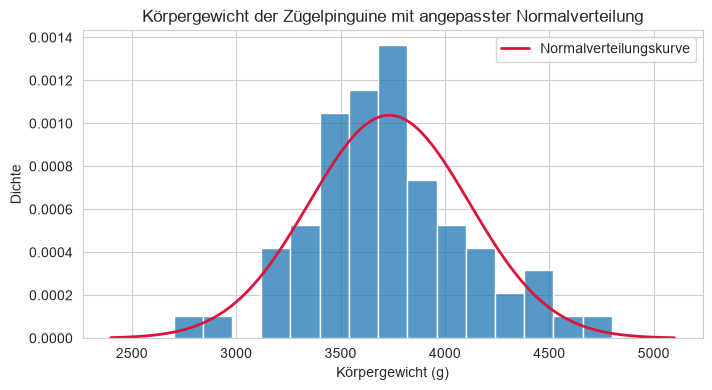

In [5]:
# 200 gleichmäßig verteilte Gewichte, etwas jenseits des leichtesten und schwersten Pinguins
x = np.linspace(mass.min() - 300, mass.max() + 300, 200)

fig, ax = plt.subplots(figsize=(8, 4))

# Dichteskala: die Gesamtfläche der Balken ist 1
sns.histplot(mass, stat="density", bins=15, ax=ax)

# die Normalverteilungskurve mit unserem Mittelwert und unserer Standardabweichung
ax.plot(x, stats.norm.pdf(x, loc=mean_mass, scale=std_mass), color="crimson", linewidth=2,
        label="Normalverteilungskurve")

ax.set_title("Körpergewicht der Zügelpinguine mit angepasster Normalverteilung")
ax.set_xlabel("Körpergewicht (g)")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()

Die Kurve folgt den Balken recht gut: ein Gipfel nahe dem Mittelwert und ein Abfall, der auf
beiden Seiten etwa gleich ist. Es ist keine perfekte Übereinstimmung und wird es mit 68 Pinguinen
auch nie sein, aber es ist eine faire Zusammenfassung der Form.

> **Hinweis.** Die Höhe der Kurve ist eine *Dichte*, keine Wahrscheinlichkeit. Die
> Wahrscheinlichkeit, dass ein Pinguin exakt 3.733,0000 g wiegt, ist null. Wahrscheinlichkeiten
> gehören zu **Bereichen** von Werten – darum geht es im nächsten Abschnitt.

> **Übung:**
>
> Mach dasselbe für die **Flossenlänge** der Zügelpinguine, `flipper_length_mm`. Berechne
> Mittelwert und Standardabweichung und zeichne dann das Histogramm auf der Dichteskala mit der
> angepassten Normalverteilungskurve darüber. Ist die Normalverteilung ein faires Modell dafür?

In [7]:
flipp = chinstrap["flipper_length_mm"]

# die zwei Zahlen, die eine Normalverteilungskurve festlegen
mean_flipp = flipp.mean()
std_flipp = flipp.std()

print(f"Mittelwert         : {mean_flipp:.1f} mm")
print(f"Standardabweichung : {std_flipp:.1f} mm")

Mittelwert         : 195.8 mm
Standardabweichung : 7.1 mm


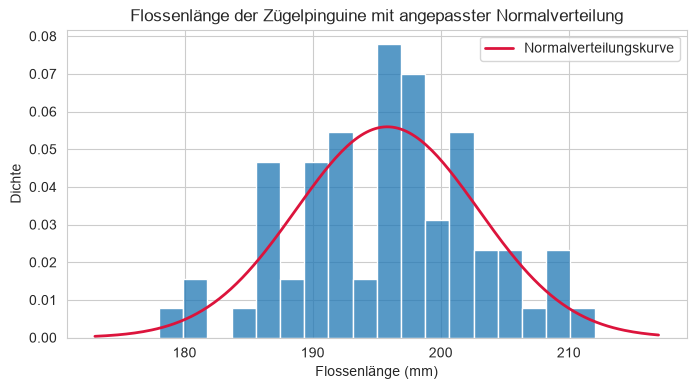

In [11]:
# 200 gleichmäßig verteilte Gewichte, etwas jenseits des leichtesten und schwersten Pinguins
x = np.linspace(flipp.min() - 5, flipp.max() + 5, 200)

fig, ax = plt.subplots(figsize=(8, 4))

# Dichteskala: die Gesamtfläche der Balken ist 1
sns.histplot(flipp, stat="density", bins=18, ax=ax)

# die Normalverteilungskurve mit unserem Mittelwert und unserer Standardabweichung
ax.plot(x, stats.norm.pdf(x, loc=mean_flipp, scale=std_flipp), color="crimson", linewidth=2,
        label="Normalverteilungskurve")

ax.set_title("Flossenlänge der Zügelpinguine mit angepasster Normalverteilung")
ax.set_xlabel("Flossenlänge (mm)")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()

In [ ]:
# dein Code: Normalverteilung für chinstrap["flipper_length_mm"] anpassen und plotten

## 2. Die Fläche unter der Kurve ist eine Wahrscheinlichkeit

Sobald die Kurve angepasst ist, hat eine Frage wie *„Wie wahrscheinlich wiegt ein Zügelpinguin
weniger als 3.500 g?“* eine präzise Antwort: Es ist die **Fläche unter der Kurve links von
3.500**. Die Gesamtfläche ist 1, also ist jeder Teil davon ein Anteil zwischen 0 und 1.

`stats.norm.cdf`, die **kumulative Verteilungsfunktion**, liefert genau diese Fläche: alles
links von dem Wert, den du übergibst.

In [ ]:
threshold = 3500

# Fläche links vom Schwellenwert unter der angepassten Kurve
p_below_model = stats.norm.cdf(threshold, loc=mean_mass, scale=std_mass)

# dieselbe Frage direkt an die 68 Pinguine gestellt
p_below_data = (mass < threshold).mean()

print(f"Modell: {p_below_model:.1%} der Zügelpinguine wiegen weniger als {threshold} g")
print(f"Daten : {p_below_data:.1%} ({(mass < threshold).sum()} von {len(mass)} Pinguinen)")

In [ ]:
x = np.linspace(mass.min() - 300, mass.max() + 300, 200)
y = stats.norm.pdf(x, loc=mean_mass, scale=std_mass)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y, color="crimson", linewidth=2)

# die Fläche schattieren, die cdf gerade gemessen hat
ax.fill_between(x, y, where=(x <= threshold), color="crimson", alpha=0.3,
                label=f"Fläche = {p_below_model:.3f}")

ax.axvline(threshold, color="black", linestyle="--")
ax.set_title(f"P(Körpergewicht < {threshold} g) unter der angepassten Normalverteilung")
ax.set_xlabel("Körpergewicht (g)")
ax.set_ylabel("Dichte")
ax.legend()
plt.show()

Das Modell sagt 27 Prozent, und tatsächlich wiegen 17 der 68 Pinguine, also 25 Prozent, weniger
als 3.500 g. Die beiden stimmen gut überein, genau wie es ein gut passendes Modell tun sollte.
Die Antwort des Modells ist außerdem *glatter*: Sie springt nicht, wenn ein einzelner Pinguin über
die Linie rutscht.

Zwei weitere Flächen ergeben sich aus derselben Funktion:

- **Oberhalb** eines Werts ist alles, was nicht unterhalb liegt: `1 - stats.norm.cdf(value, ...)`.
- **Zwischen** zwei Werten ist die Fläche links vom oberen minus die Fläche links vom unteren:
  `stats.norm.cdf(upper, ...) - stats.norm.cdf(lower, ...)`.

> **Übung:**
>
> Mit der Normalverteilung, die du an die Flossenlänge der Zügelpinguine angepasst hast:
>
> 1. Welcher Anteil der Zügelpinguine hat laut Modell Flossen **länger als 200 mm**?
>    Vergleiche ihn mit dem Anteil in den Daten.
> 2. Welchen Anteil sieht das Modell **zwischen 190 und 200 mm**?

<details><summary>
Hier klicken für einen Tipp ...
</summary>

`mean_flipper` und `std_flipper` hast du schon aus der letzten Übung. Übergib sie als `loc` und
`scale`. Für den Anteil in den Daten funktioniert `(flipper > 200).mean()` genauso wie im
Körpergewicht-Beispiel oben.
</details>

In [ ]:
# dein Code: länger als 200 mm, Modell und Daten

In [ ]:
# dein Code: zwischen 190 und 200 mm

## 3. Rückwärts: von einer Wahrscheinlichkeit zu einem Wert

`cdf` nimmt einen Wert und gibt eine Fläche zurück. Ihre Umkehrfunktion, `stats.norm.ppf` (die
*Quantilfunktion*, engl. *percent point function*), nimmt eine Fläche und gibt den Wert zurück,
der sie abschneidet.

Die Frage, die sie am häufigsten beantwortet, lautet: **Welcher Bereich enthält die mittleren
95 Prozent?** Schneide an jedem Rand 2,5 Prozent ab und lies die beiden Werte ab, an denen die
Schnitte liegen.

In [ ]:
# die Werte, die in jedem Rand 2,5 % der Fläche übrig lassen
lower, upper = stats.norm.ppf([0.025, 0.975], loc=mean_mass, scale=std_mass)
print(f"mittlere 95 % des Körpergewichts der Zügelpinguine: {lower:.0f} g bis {upper:.0f} g")

# wie viele unserer Pinguine liegen tatsächlich in diesem Bereich?
inside = mass.between(lower, upper)
print(f"Pinguine im Bereich: {inside.sum()} von {len(mass)} ({inside.mean():.1%})")

Das Modell legt die mittleren 95 Prozent der Zügelpinguine zwischen etwa 2.980 g und 4.486 g,
und 63 unserer 68 Pinguine liegen darin.

### z-Werte und die Zahl 1,96

Ein Abstand in Gramm bedeutet nur dann etwas, wenn man weiß, wie stark die Gewichte streuen. Der
**z-Wert** entfernt die Einheiten, indem er stattdessen in Standardabweichungen zählt:

$$
z = \frac{x - \mu}{\sigma}
$$

Ein z-Wert von 0 ist genau durchschnittlich; +2 liegt zwei Standardabweichungen darüber. Rechnet
man jeden Wert so um, wird aus jeder Normalverteilung dieselbe, die **Standardnormalverteilung**
mit Mittelwert 0 und Standardabweichung 1. Das ist `stats.norm` ganz ohne `loc` oder `scale`.

Frag die Standardnormalverteilung, wo ihre mittleren 95 Prozent enden:

In [ ]:
# kein loc oder scale: die Standardnormalverteilung, Mittelwert 0 und Standardabweichung 1
z_crit = stats.norm.ppf(0.975)
print(f"die mittleren 95 % jeder Normalverteilung liegen innerhalb von {z_crit:.2f} "
      "Standardabweichungen um ihren Mittelwert")

**Merk dir 1,96.** Das gilt für jede Normalverteilung, egal was sie misst, und kommt in diesem
Repository zweimal wieder: In `02_sampling_and_confidence_intervals.ipynb` baut es ein
Konfidenzintervall, und in `03_how_a_test_works.ipynb` ist es die Linie, die ein Testergebnis
überschreiten muss, um als überraschend zu gelten.

Nimm jetzt einen schweren Zügelpinguin mit 4.500 g und frag, wie ungewöhnlich er ist.

In [ ]:
heavy = 4500

# wie viele Standardabweichungen über dem Mittelwert?
z_heavy = (heavy - mean_mass) / std_mass
print(f"z-Wert eines Zügelpinguins mit {heavy} g: {z_heavy:.2f}")

# die Fläche dahinter, auf zwei Arten gefragt: auf der Gramm-Skala und auf der z-Skala
print(f"schwerer als dieser, Gramm-Skala: {1 - stats.norm.cdf(heavy, loc=mean_mass, scale=std_mass):.2%}")
print(f"schwerer als dieser, z-Skala    : {1 - stats.norm.cdf(z_heavy):.2%}")

Ein Zügelpinguin mit 4.500 g liegt 2,0 Standardabweichungen über dem Mittelwert, und laut Modell
sind nur etwa 2,3 Prozent der Zügelpinguine schwerer. Beide Skalen liefern dieselbe Fläche, weil
der z-Wert nur die Achse umbeschriftet.

Genau so wird ein Hypothesentest in Notebook 03 ein Ergebnis beurteilen: Es wird umgerechnet in
*wie viele Standardeinheiten es von dem entfernt liegt, was wir erwartet haben*, und dann wird
gemessen, *wie viel Fläche dahinter liegt*. Eine kleine Fläche bedeutet ein überraschendes
Ergebnis.

> **Übung:**
>
> Zurück zur Flossenlänge der Zügelpinguine.
>
> 1. Welcher Bereich enthält laut Modell die mittleren 95 Prozent der Flossenlängen?
> 2. Wie hoch ist der z-Wert eines Zügelpinguins mit 210 mm Flossenlänge, und welcher Anteil der
>    Zügelpinguine hat laut Modell eine mindestens so lange Flosse?

In [ ]:
# dein Code: die mittleren 95 % der Flossenlängen

In [ ]:
# dein Code: z-Wert einer 210-mm-Flosse und der Anteil mit mindestens dieser Länge

## 4. Wenn die Normalverteilung das falsche Modell ist

Jede bisherige Berechnung hat der angepassten Kurve vertraut. Dieses Vertrauen war verdient, weil
wir zuerst das Histogramm angesehen und jeweils **nur eine Art** modelliert haben. Die nächste
Übung zeigt, was ohne diese Sorgfalt passiert.

> **Übung:**
>
> Nimm das Körpergewicht **aller** Pinguine, alle Arten zusammen.
>
> 1. Entferne die zwei fehlenden Werte, passe eine Normalverteilung an und zeichne sie wie in
>    Abschnitt 1 über das Histogramm.
> 2. Frag das Modell, welcher Anteil der Pinguine weniger als 3.000 g wiegt, und vergleiche es
>    mit den Daten. Mach dann dasselbe für weniger als 2.700 g.
> 3. In ein, zwei Sätzen: Warum liegt das Modell hier falsch?

<details><summary>
Hier klicken für einen Tipp ...
</summary>

`df_penguins["body_mass_g"].dropna()` liefert die 342 Gewichte. Für Frage 3 färbe das Histogramm
nach Art ein: `sns.histplot(data=df_penguins, x="body_mass_g", hue="species",
multiple="stack")`.
</details>

In [ ]:
# dein Code: Normalverteilung für das Körpergewicht aller Pinguine anpassen und plotten

In [ ]:
# dein Code: Modell und Daten unter 3.000 g und unter 2.700 g vergleichen

In [ ]:
# dein Code (optional): Histogramm nach Art einfärben, um den Grund zu sehen

<details><summary>
Hier klicken, um deine Antwort auf Frage 3 zu vergleichen ...
</summary>

Das Modell sieht etwa 6,7 Prozent der Pinguine unter 3.000 g, die Daten 2,6 Prozent, und etwa
3 Prozent unter 2.700 g, wo die Daten gar keine haben: Der leichteste Pinguin wiegt genau
2.700 g.

Die Daten sind keine einzelne Glocke, sondern eine **Mischung**. Adeliepinguine und
Zügelpinguine wiegen im Schnitt etwa 3.700 g, Eselspinguine (Gentoo) etwa 5.100 g. Zusammengelegt
ergeben sie eine schiefe Form mit einem zweiten Buckel rechts. Eine einzelne Normalverteilung
kann sich nicht so biegen, also dehnt sie sich breit, um beide Buckel abzudecken, und lässt ihren
linken Rand in Gewichte auslaufen, die kein Pinguin hat.
</details>

Die Lektion gilt für jeden folgenden Test: **Schau dir das Histogramm an, bevor du der Kurve
vertraust.** Die Tests in den Notebooks 03 bis 05 machen Annahmen über die Form der Daten, und
deren Überprüfung beginnt mit einem Plot.

## 5. Kurven für Testergebnisse

Jede bisherige Kurve hat **Daten** beschrieben: hier Pinguingewichte und Zählungen in der Tabelle
aus Abschnitt 1. Hypothesentests brauchen eine zweite Art von Kurve. Ein Test verdichtet einen
ganzen Datensatz auf **eine Zahl**, seine *Teststatistik*, und fragt dann, wo diese Zahl auf einer
Kurve liegt, die beschreibt, wie sie allein durch Zufall schwanken würde.

Diese Kurven passt du nie an eine Spalte an, und scipy verwendet sie für dich. Aber drei von ihnen
erledigen die gesamte Arbeit in diesem Repository, also lohnt es sich, sie einmal zu sehen, bevor
sie wichtig werden:

| Kurve | Was die Teststatistik misst | Wo sie dir begegnet |
| :--- | :--- | :--- |
| **t** | wie weit ein Mittelwert von einem behaupteten Wert entfernt liegt, in Standardfehlern | Notebooks 02 und 03, dann t-Test und Korrelationstest in 04 |
| **Chi-Quadrat** | wie weit die Häufigkeiten in einer Tabelle von denen abweichen, die man erwarten würde, wenn zwei Spalten unabhängig wären | Chi-Quadrat-Test in 04 |
| **F** | wie weit mehrere Gruppenmittelwerte auseinanderliegen, verglichen mit der Streuung innerhalb jeder Gruppe | ANOVA in 04 |

Jede hat einen Formparameter namens **Freiheitsgrade**, der davon abhängt, wie viele Daten in die
Statistik eingeflossen sind. Der Plot zeigt jede Kurve mit zwei Einstellungen; die durchgezogene
Linie in jedem Feld ist die Einstellung, die die Beispiele in den Notebooks 03 und 04 verwenden.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# t: glockenförmig um 0, wie die Standardnormalverteilung (gepunktet), aber mit schwereren Rändern
x = np.linspace(-4, 4, 400)
axes[0].plot(x, stats.norm.pdf(x), color="black", linestyle=":", label="Standardnormalverteilung")
axes[0].plot(x, stats.t.pdf(x, df=67), color="crimson", linewidth=2, label="t, FG = 67")
axes[0].plot(x, stats.t.pdf(x, df=3), color="steelblue", linestyle="--", label="t, FG = 3")
axes[0].set_title("t: Mittelwerte, in Standardfehlern")

# Chi-Quadrat: aus quadrierten Abständen gebaut, beginnt also bei 0 und wird nie negativ
x = np.linspace(0.05, 12, 400)
axes[1].plot(x, stats.chi2.pdf(x, df=1), color="crimson", linewidth=2, label="Chi-Quadrat, FG = 1")
axes[1].plot(x, stats.chi2.pdf(x, df=4), color="steelblue", linestyle="--",
             label="Chi-Quadrat, FG = 4")
axes[1].set_ylim(0, 0.8)
axes[1].set_title("Chi-Quadrat: Häufigkeiten in einer Tabelle")

# F: ein Verhältnis zweier Streuungen, beginnt also auch bei 0; hat zwei Freiheitsgrade
x = np.linspace(0.01, 5, 400)
axes[2].plot(x, stats.f.pdf(x, dfn=3, dfd=240), color="crimson", linewidth=2,
             label="F, FG = 3 und 240")
axes[2].plot(x, stats.f.pdf(x, dfn=2, dfd=10), color="steelblue", linestyle="--",
             label="F, FG = 2 und 10")
axes[2].set_title("F: mehrere Gruppenmittelwerte")

for ax in axes:
    ax.set_ylabel("Dichte")
    ax.legend()

plt.tight_layout()
plt.show()

Drei Dinge, die du aus dem Bild mitnehmen solltest:

- **t** ist ein enger Verwandter der Standardnormalverteilung: um 0 zentriert, symmetrisch, mit
  schwereren Rändern, wenn es wenige Freiheitsgrade gibt. Bei 67, der Einstellung, die
  Notebook 03 für die 68 Zügelpinguine verwendet, ist sie kaum von der Normalverteilung zu
  unterscheiden.
- **Chi-Quadrat** und **F** beginnen bei 0 und laufen nach rechts aus. Ihre Statistiken sind aus
  quadrierten Abständen und Verhältnissen von Streuungen gebaut, können also nie negativ sein, und
  nur ein **großer** Wert ist überraschend.
- **Flächen funktionieren genau wie in Abschnitt 2.** `stats.t`, `stats.chi2` und `stats.f` haben
  alle `cdf` und `ppf`, genau wie `stats.norm`. Jeder p-Wert in diesem Repository ist eine Fläche
  unter einer dieser drei Kurven.

## Zusammenfassung

In diesem Notebook hast du:

- einer Spalte anhand ihres Typs und ihrer Form eine Verteilung zugeordnet.
- eine Normalverteilung mit zwei Zahlen, Mittelwert und Standardabweichung, an das Körpergewicht
  der Zügelpinguine angepasst.
- mit `stats.norm.cdf` Wahrscheinlichkeiten als Flächen von dieser Kurve abgelesen.
- mit `stats.norm.ppf` den Weg von einer Fläche zurück zu einem Wert gefunden und 1,96
  kennengelernt.
- mit dem z-Wert gemessen, wie ungewöhnlich ein Wert ist.
- gesehen, wie eine Normalverteilung an Daten scheitert, die eigentlich eine Mischung aus drei
  Gruppen sind.
- die drei Kurven kennengelernt, mit denen Tests ihre Ergebnisse vergleichen: t, Chi-Quadrat
  und F.

Alles hier hat **einzelne Pinguine** beschrieben. Das nächste Notebook fragt nach dem
**durchschnittlichen** Pinguin: Hättest du 68 andere Zügelpinguine gewogen, wie stark hätte sich
der Mittelwert verändert? Die Antwort ist wieder eine Normalverteilung, und 1,96 kommt direkt
zurück.

## Quellen & weiterführende Literatur

- [**scipy.stats.norm**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html):
  Die Normalverteilung mit `pdf`, `cdf`, `ppf` und ihren übrigen Methoden.
  [`scipy.stats.t`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html),
  [`chi2`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html) und
  [`f`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f.html)
  haben dieselben Methoden.
- [**Seeing Theory: Probability Distributions**](https://seeing-theory.brown.edu/probability-distributions/index.html):
  Interaktive, visuelle Erklärungen der Verteilungen aus der Tabelle in Abschnitt 1.
- [**seaborn.histplot**](https://seaborn.pydata.org/generated/seaborn.histplot.html):
  Das durchgehend verwendete Histogramm, inklusive der Option `stat="density"`.
- [**palmerpenguins**](https://allisonhorst.github.io/palmerpenguins/): Die Herkunft des
  Datensatzes, erhoben von Dr. Kristen Gorman an der Palmer-Station in der Antarktis.